# Find coherence of 100, 500, 1000 LDA model 

In [ ]:
import pandas as pd
import gensim
import pickle
import gc
from tqdm import tqdm
import matplotlib.pyplot as plt
import logging


S=5000000

In [5]:
def text_preprocess(text):

    from nltk.stem  import PorterStemmer 
    from nltk.stem import WordNetLemmatizer



    import gensim
    import string
    

    ps = PorterStemmer()

    if text=="":
        return []
    
    
    result = []
    for token in gensim.utils.simple_preprocess(text):
       
        if token not in gensim.parsing.preprocessing.STOPWORDS and len(token) > 3:
            result.append(ps.stem(WordNetLemmatizer().lemmatize(token, pos='v') ))

    return result


In [ ]:

from gensim.models import Phrases
#from gensim.models.phrases import Phraser
import gensim
from tqdm import tqdm
import pickle



class SentenceIterator:
    def __init__(self, filepath):
        self.filepath = filepath

    def __iter__(self):
        for line in open(self.filepath, encoding="utf-8"):  # Ensure correct encoding
            yield line.split()[1:]   # Tokenized sentences (skip the first token if needed)

# Load sentences
sentences = SentenceIterator("D:\\New-patents\\Landscaping\\data\\fulltext_preprocessed.tsv")



In [7]:
# bigrams V3
bigram = Phrases(sentences, scoring="npmi", threshold=0.5, min_count=1)

In [ ]:

g=open("./data/bigrams_new_data", "wb")
pickle.dump(bigram, g)
g.close



In [ ]:

f=open("./data/fulltext_with_bigrams_new_data.tsv", "w")
g =open("D:\\New-patents\\Landscaping\\data\\fulltext_preprocessed.tsv")
l=g.readline()# header

while (True):
    l=g.readline()
    if not l:
        break
    s=l.split()

    pnumber=s[0]
    s=s[1:]
    news=s
    for token in bigram[s]:
        if '_' in token:
            # Token is a bigram, add to document.
            news.append(token)
    f.write(pnumber+'\t'+ (' '.join(news))+'\n')        


f.close()
g.close()


In [10]:
import gensim
import pickle
class SentenceIterator:
    def __init__(self, filepath):
        self.filepath = filepath

    def __iter__(self):
        for line in open(self.filepath, encoding="utf-8"):  # Ensure correct encoding
            yield line.split()[1:]   # Tokenized sentences (skip the first token if needed)
docs=SentenceIterator("./data/fulltext_with_bigrams_new_data.tsv")


In [11]:
dictionary = gensim.corpora.Dictionary(docs)


# Filter out words that occur less than 10 documents, or more than 50% of the documents.
dictionary.filter_extremes(no_below=10, no_above=0.5)

f=open(f"./data/dictionary_with_bigrams_new_data", "wb")
pickle.dump(dictionary,f)
f.close()


In [2]:
import pickle
f=open("./data/dictionary_with_bigrams_new_data", "rb")
dictionary=pickle.load(f)
f.close()

In [13]:
len(dictionary)

100000

In [ ]:
import random

# Set seed once
random.seed(42)

def save_sampled_data(input_file, output_file, sample_percent=10):
    """Save the sampled data to a new file once"""
    # Count total lines
    with open(input_file, encoding="utf-8") as f:
        total_lines = sum(1 for _ in f)
    
    sample_size = int(total_lines * sample_percent / 100)
    
    # Select random indices
    selected_indices = set(random.sample(range(total_lines), sample_size))
    
    # Write selected lines to new file
    with open(input_file, encoding="utf-8") as infile, \
         open(output_file, 'w', encoding="utf-8") as outfile:
        for idx, line in enumerate(infile):
            if idx in selected_indices:
                outfile.write(line)
    
    print(f"Saved {len(selected_indices)} lines ({sample_percent}%) to {output_file}")
    return output_file

# RUN ONCE: Create the sampled file
sampled_file = save_sampled_data(
    "./data/fulltext_with_bigrams_new_data.tsv",
    "./data/sampled_10_percent.tsv",
    sample_percent=10
)

# Now use this file in your iterator (no random needed)
class SentenceIterator:
    def __init__(self, filepath):
        self.filepath = filepath
        
    def __iter__(self):
        with open(self.filepath, encoding="utf-8") as f:
            for line in f:
                yield dictionary.doc2bow(line.split()[1:])

# This will always use the SAME 10% data
sentences = SentenceIterator("./data/sampled_10_percent.tsv")

In [47]:
for num in [100,500,1000]:
    ldamodel = gensim.models.LdaMulticore(sentences,  id2word=dictionary, num_topics=num, passes=7, workers=24)
    ldamodel.save(f"./data/lda_{num}_model_bigrams_new_data_10percent")


In [48]:
from gensim.models import CoherenceModel
#from gensim.utils import simple_preprocess
coherences = {}
for k in [100,500, 1000]: 
    ldamodel = gensim.models.ldamodel.LdaModel.load(f"./data/lda_{k}_model_bigrams_new_data_10percent")
    cm = CoherenceModel(model=ldamodel, texts=docs, dictionary=dictionary, coherence='c_v') 
    coherences[k] = cm.get_coherence()

In [49]:
coherences

{100: 0.5032934354709081, 500: 0.4290596887709654, 1000: 0.38703717455602044}

## Plot coherence

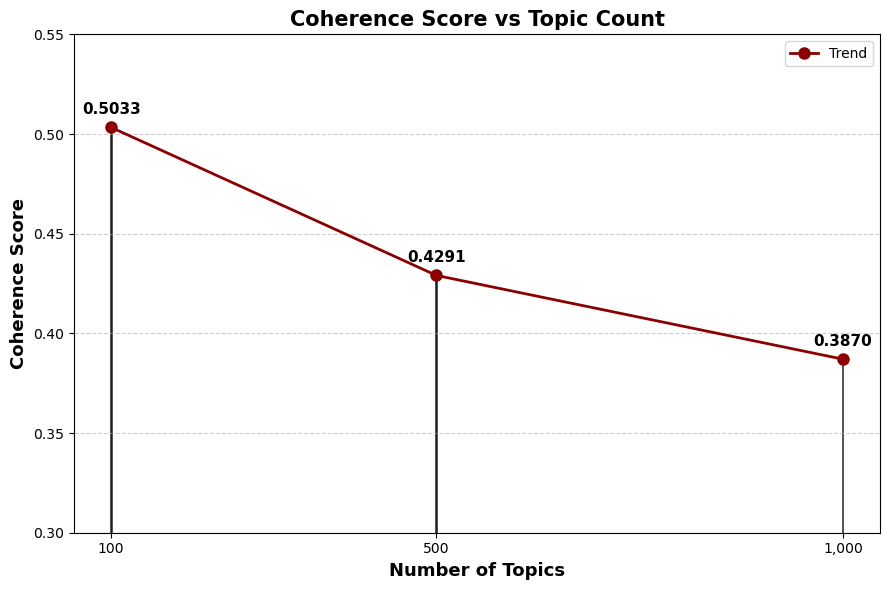

In [1]:
import matplotlib.pyplot as plt
import numpy as np

coherence_scores = {100: 0.5032934354709081, 500: 0.4290596887709654, 1000: 0.38703717455602044}

fig, ax = plt.subplots(figsize=(9, 6))

# Bar chart
bars = ax.bar(coherence_scores.keys(), coherence_scores.values(), 
              color='steelblue', alpha=0.8, edgecolor='black', linewidth=1.2)

# Add a trend line
x_values = list(coherence_scores.keys())
y_values = list(coherence_scores.values())
ax.plot(x_values, y_values, 'o-', color='darkred', linewidth=2, 
        markersize=8, label='Trend')

# Add value labels
for bar, value in zip(bars, y_values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{value:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Customize
ax.set_xlabel('Number of Topics', fontsize=13, fontweight='bold')
ax.set_ylabel('Coherence Score', fontsize=13, fontweight='bold')
ax.set_title('Coherence Score vs Topic Count', fontsize=15, fontweight='bold')
ax.set_ylim(0.3, 0.55)  # Adjust based on your data
ax.grid(axis='y', linestyle='--', alpha=0.6)
ax.legend()

# Format x-axis tick labels
ax.set_xticks(list(coherence_scores.keys()))
ax.set_xticklabels([f'{k:,}' for k in coherence_scores.keys()])

plt.savefig('coherence_scores.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

## Check 100 topics model and evaluation

In [3]:
import numpy as np
import gensim
import pandas as pd
import pickle
data=pd.read_csv("./data/llm_without_chunks.csv")

for k in [100,500]:
    final_ldamodel = gensim.models.ldamodel.LdaModel.load(f"./data/lda_{k}_model_bigrams_new_data_10percent")
    topic_dict={}

    
    for j in range(0,len(data)):
        id = int(data.iloc[j]["patent_id"])
        topics = final_ldamodel[dictionary.doc2bow(data.iloc[j]["patent_text"].split())]
        topic_dict.update({id:topics})

    f=open(f'./data/patent_topic_sampled_10_{k}', 'wb')
    pickle.dump(topic_dict,f)
    f.close()

In [4]:
topic_dict

{5376962: [(16, 0.16846952),
  (26, 0.011778729),
  (36, 0.1628717),
  (166, 0.022503333),
  (203, 0.027619906),
  (207, 0.20829059),
  (239, 0.018934797),
  (279, 0.010716212),
  (359, 0.11507711),
  (395, 0.054008055),
  (408, 0.033399906),
  (420, 0.039971955),
  (443, 0.019478338),
  (463, 0.0965878)],
 6625588: [(16, 0.0956413),
  (32, 0.03557355),
  (36, 0.16034189),
  (41, 0.03510767),
  (154, 0.06281153),
  (207, 0.28627506),
  (245, 0.05202275),
  (297, 0.010733812),
  (359, 0.024461064),
  (362, 0.028701693),
  (395, 0.05576711),
  (408, 0.07194681),
  (463, 0.050324973)],
 5568413: [(16, 0.13353819),
  (32, 0.017397797),
  (41, 0.1238916),
  (98, 0.018532278),
  (146, 0.011752429),
  (154, 0.0495276),
  (203, 0.03734008),
  (207, 0.2798995),
  (249, 0.026637396),
  (258, 0.0136495475),
  (344, 0.011651364),
  (359, 0.104687855),
  (408, 0.04653273),
  (420, 0.045699276),
  (463, 0.051299762)],
 9760850: [(16, 0.2449317),
  (36, 0.09338481),
  (52, 0.018450815),
  (116, 0.017

In [ ]:

#v2 (cosine similarity)
from gensim.matutils import cossim
for k in [100,500]:
    final_ldamodel = gensim.models.ldamodel.LdaModel.load(f"./data/lda_{k}_model_bigrams_new_data_10percent")
    def CosineSimilarity(topic1, topic2):
        # Convert words to ids
        # topic1_ids = [(id2word.token2id[word], score) for word, score in topic1 if word in id2word.token2id]
        # topic2_ids = [(id2word.token2id[word], score) for word, score in topic2 if word in id2word.token2id]

        return cossim(topic1, topic2)

    def top_words_topic(topic_number):#this fuction find ten top words of a topic
        list_words=[]
        topic=final_ldamodel.show_topic(topic_number, topn=100)
        for i in range(len(topic)):
            words=topic[i][0]
            list_words.append(words)
        return list_words     
    def top_score_topic(topic_number):#this fuction find ten top words of a topic
        list_scores=[]
        topic=final_ldamodel.show_topic(topic_number,  topn=100)
        for i in range(len(topic)):
            scores=topic[i][1]
            list_scores.append(scores)
        return list_scores 
    def find_words_topics(list1):#this function finds  the list of top words of each topics of list
        
        listtopics1=[]
        
        for i in range(len(list1)):
            topics1=top_words_topic(list1[i][0])
            listtopics1.append(topics1)
            
    
    
        return listtopics1
    def find_score_of_words_topics(list1):#this function find list of score of top words of each topics of list
        
        listtopics1=[]
        
        for i in range(len(list1)):
            topics1=top_score_topic(list1[i][0])
        
            listtopics1.append(topics1)
        return listtopics1    

    simil_matrix_ws={}
    listtopics1=   find_words_topics( list(zip(range(final_ldamodel.num_topics) , [0]*final_ldamodel.num_topics) ))
    listscores1=   find_score_of_words_topics(list(zip(range(final_ldamodel.num_topics), [0] *final_ldamodel.num_topics  )))


    list_topics=[]
    for i in range(len(listtopics1)):     
        tuples= list(zip(listtopics1[i],listscores1[i]))
        list_topics.append(tuples)


    print(list_topics)

    for i,topic1 in enumerate(list_topics):
        print(i)
        for j,topic2 in enumerate(list_topics):
                
                
            
                simil_matrix_ws[(i,j)]=CosineSimilarity(topic1, topic2) #V2 (cosine similarity)


    f=open(f"./data/simil_matrices_phrases_samples_10_{k}", "wb")

    pickle.dump([simil_matrix_ws], f)
    f.close()    

In [9]:
llm = pd.read_csv("./data/llm_without_chunks.csv")
llm

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,their_score_planning,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.923894,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.007498,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.530319,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.999981,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.001134,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.000004,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000116,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000207,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003473,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
# 100
# kewword V3
from nltk.stem  import PorterStemmer
from nltk.stem import WordNetLemmatizer
from gensim.models import Phrases
from gensim.models.phrases import Phraser
def text_preprocess(text):

    ps = PorterStemmer()

    if text=="":
        return []


    result = []
    for token in gensim.utils.simple_preprocess(text):

        if token not in gensim.parsing.preprocessing.STOPWORDS and len(token) > 2:
            result.append(ps.stem(WordNetLemmatizer().lemmatize(token, pos='v') ))

    return result
keywords = []
with open("D:\\New-patents\\Landscaping\\data\\keywords3-new.txt", "r", encoding='utf8') as F:
    lines = F.readlines()
    iter = [text_preprocess(line) for line in lines]
    for list_keyword in iter:
        keyword = "_".join(list_keyword)
        keywords.append(keyword)
keywords = set(keywords)
keywords = list(keywords)
print(keywords)

['autoencod', 'optimis', 'represent', 'gaussian_process', 'comput_intellig', 'search_engin', 'wheel', 'speech', 'retriev', 'support_vector', 'bootstrap', 'gradient_boost', 'tree_boost', 'meta_learn', 'generalis', 'adaboost', 'neuron', 'collabor', 'visual_stimuli', 'virtual_realiti', 'localis_map', 'region_polici', 'term_memori', 'gradient_method', 'polici_gradient', 'ensembl_learn', 'semant_network', 'dimension_input', 'process_data', 'spars', 'leg', 'extract_inform', 'deep_learn', 'quadrup', 'bayesian', 'assist', 'extract_knowledg', 'signal_separ', 'speech_synthesi', 'coloni_algorithm', 'decis_tree', 'softwar', 'patholog', 'random', 'featur_learn', 'interfac', 'imag_process', 'rankboost', 'relat_learn', 'bayesian_network', 'artifici', 'hierarch_cluster', 'factoris', 'multitask_learn', 'object', 'avoid', 'collabor_filter', 'virtual_assist', 'retina', 'textto_speech', 'layer', 'fusion', 'memori', 'lstm', 'compon_analysi', 'multi_label', 'trajectori', 'imag_segment', 'speech_segment', 'p

In [15]:
# kewword V3
from nltk.stem  import PorterStemmer
from nltk.stem import WordNetLemmatizer
from gensim.models import Phrases
from gensim.models.phrases import Phraser
import ast

keywords_ml = []
keywords_evo = []
keywords_nlp = []
keywords_speech = []
keywords_vision = []
keywords_kr = []
keywords_planning = []
keywords_hardware = []

with open("./data/keywords_with_8cat.txt", "r", encoding='utf8') as F:
    lines = F.readlines()
    c=0
    for line in lines:
        if c == 1:
            keywords_ml = ast.literal_eval(line)
        if c == 3:
            keywords_evo = ast.literal_eval(line)
        if c == 5:
            keywords_nlp = ast.literal_eval(line)
        if c == 7:
            keywords_speech = ast.literal_eval(line)
        if c == 9:
            keywords_vision = ast.literal_eval(line)
        if c == 11:
            keywords_kr = ast.literal_eval(line)
        if c == 13:
            keywords_planning = ast.literal_eval(line)
        if c == 15:
            keywords_hardware = ast.literal_eval(line)

        c += 1


keywords = set(keywords_ml)
keywords_ml1 = list(keywords)
print(keywords_ml1)
keywords = set(keywords_evo)
keywords_evo1 = list(keywords)
print(keywords_evo1)
keywords = set(keywords_nlp)
keywords_nlp1 = list(keywords)
print(keywords_nlp1)
keywords = set(keywords_speech)
keywords_speech1 = list(keywords)
print(keywords_speech1)
keywords = set(keywords_vision)
keywords_vision1 = list(keywords)
print(keywords_vision1)
keywords = set(keywords_kr)
keywords_kr1 = list(keywords)
print(keywords_kr1)
keywords = set(keywords_planning)
keywords_planning1 = list(keywords)
print(keywords_planning1)
keywords = set(keywords_hardware)
keywords_hardware1 = list(keywords)
print(keywords_hardware1)


['deep_neural', 'classif', 'stack', 'data_mine', 'associ_rule', 'factoris_machin', 'cluster', 'bootstrap_aggreg', 'bayesian_learn', 'machin', 'regress', 'sensor_data', 'recurr', 'reduct', 'collabor', 'dimension_reduct', 'data', 'dimension_data', 'tree_boost', 'linkag_cluster', 'polici_optimis', 'rule_learn', 'high_dimension', 'long_short', 'hierarch', 'kernel', 'pattern_recognit', 'dictionari_learn', 'short_term', 'instanc_base', 'meta_learn', 'predict', 'lstm', 'sensor_fusion', 'perceptron', 'autoencod', 'fuzzi_number', 'unsupervis', 'ensembl', 'madaboost', 'network', 'convolut_neural', 'similar_learn', 'rule_base', 'transfer_learn', 'adversari', 'adapt_boost', 'featur_extract', 'latent_represent', 'tempor', 'process', 'markov', 'deep', 'collabor_filter', 'xgboost', 'factoris', 'trust_region', 'ensembl_learn', 'cluster_analysi', 'fuzzi', 'latent_dirichlet', 'dirichlet', 'gener_adversari', 'graph', 'spectral', 'supervis_learn', 'model', 'backpropag', 'hebbian_learn', 'fuzzi_set', 'grad

In [ ]:

for k in [100, 500]:
    ldamodel = gensim.models.ldamodel.LdaModel.load(f"./data/lda_{k}_model_bigrams_new_data_10percent")
    bow_vector = dictionary.doc2bow(keywords_ml1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_ml = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_evo1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_evo = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_nlp1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_nlp = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_speech1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_speech = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_vision1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_vision = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_kr1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_kr = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_planning1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_planning = sorted(keyword_topics, key=lambda x: x[1],reverse=True)
    bow_vector = dictionary.doc2bow(keywords_hardware1)
    keyword_topics = ldamodel.get_document_topics(bow_vector)
    keywords_hardware = sorted(keyword_topics, key=lambda x: x[1],reverse=True)

    simil_matrix_ws={}
    with open(f"./data/simil_matrices_phrases_samples_10_{k}", 'rb') as f:
        simil_matrix_ws=pickle.load(f)
    simil_matrix_ws = simil_matrix_ws[0]
    def text_similarity_weighted(list1,list2):
        sum=0
        for i in range(len(list1)):
            for j in range(len(list2)):
                num_topics1=list1[i][0]
                num_topics2=list2[j][0]
                similarity_distance=simil_matrix_ws[(num_topics1,num_topics2)]
                prob1=list1[i][1]
                prob2=list2[j][1]
                sum+=prob2*prob1*similarity_distance
        return(sum)
    with open(f'./data/patent_topic_sampled_10_{k}', 'rb') as f:
        patent_topics_dict=pickle.load(f)
    
    df_keyword = keywords_ml
    dictionary_similarity_ml = {}

    print(1)

    for key, value in patent_topics_dict.items():

        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_ml[key] = similarity
            



    df_keyword = keywords_evo
    dictionary_similarity_evo = {}

    print(2)

    for key, value in patent_topics_dict.items():


        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_evo[key] = similarity
            


    df_keyword = keywords_nlp
    dictionary_similarity_nlp = {}

    print(3)

    for key, value in patent_topics_dict.items():


        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_nlp[key] = similarity
            

    df_keyword = keywords_speech
    dictionary_similarity_speech = {}

    print(4)

    for key, value in patent_topics_dict.items():


        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_speech[key] = similarity


    df_keyword = keywords_vision
    dictionary_similarity_vision = {}

    print(5)

    for key, value in patent_topics_dict.items():

        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_vision[key] = similarity


    df_keyword = keywords_kr
    dictionary_similarity_kr = {}

    print(6)

    for key, value in patent_topics_dict.items():


        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_kr[key] = similarity
            


    df_keyword = keywords_planning
    dictionary_similarity_planning = {}

    print(7)

    for key, value in patent_topics_dict.items():

        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_planning[key] = similarity
            


    df_keyword = keywords_hardware
    dictionary_similarity_hardware = {}

    print(8)

    for key, value in patent_topics_dict.items():

        similarity = text_similarity_weighted(df_keyword,value)

        dictionary_similarity_hardware[key] = similarity


    import pandas as pd
    import csv

    csv_file = './data/similarity_phrases_cat_ml_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_ml.items():
            writer.writerow([key, value])


    df_ml = pd.read_csv('./data/similarity_phrases_cat_ml_all.csv')

    csv_file = './data/similarity_phrases_cat_evo_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_evo.items():
            writer.writerow([key, value])


    df_evo = pd.read_csv('./data/similarity_phrases_cat_evo_all.csv')

    csv_file = './data/similarity_phrases_cat_hardware_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_hardware.items():
            writer.writerow([key, value])


    df_hardware = pd.read_csv('./data/similarity_phrases_cat_hardware_all.csv')

    csv_file = './data/similarity_phrases_cat_nlp_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_nlp.items():
            writer.writerow([key, value])


    df_nlp = pd.read_csv('./data/similarity_phrases_cat_nlp_all.csv')


    csv_file = './data/similarity_phrases_cat_kr_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_kr.items():
            writer.writerow([key, value])


    df_kr = pd.read_csv('./data/similarity_phrases_cat_kr_all.csv')

    csv_file = './data/similarity_phrases_cat_planning_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_planning.items():
            writer.writerow([key, value])


    df_planning = pd.read_csv('./data/similarity_phrases_cat_planning_all.csv')

    csv_file = './data/similarity_phrases_cat_speech_all.csv'
    with open(csv_file, 'w', newline='') as file: 
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_speech.items():
            writer.writerow([key, value])


    df_speech = pd.read_csv('./data/similarity_phrases_cat_speech_all.csv')

    csv_file = './data/similarity_phrases_cat_vision_all.csv'
    with open(csv_file, 'w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Num_patent","Similarity"])
        for key, value in dictionary_similarity_vision.items():
            writer.writerow([key, value])


    df_vision = pd.read_csv('./data/similarity_phrases_cat_vision_all.csv')



    llm[f"similarity_{k}_ml"] = df_ml["Similarity"]
    llm[f"similarity_{k}_evo"] = df_evo["Similarity"]
    llm[f"similarity_{k}_hardware"] = df_hardware["Similarity"]
    llm[f"similarity_{k}_nlp"] = df_nlp["Similarity"]
    llm[f"similarity_{k}_kr"] = df_kr["Similarity"]
    llm[f"similarity_{k}_planning"] = df_planning["Similarity"]
    llm[f"similarity_{k}_speech"] = df_speech["Similarity"]
    llm[f"similarity_{k}_vision"] = df_vision["Similarity"]

In [14]:
#100
ldamodel = gensim.models.ldamodel.LdaModel.load("./data/lda_100_model_bigrams_new_data_10percent")
bow_vector = dictionary.doc2bow(keywords)
keyword_topics = ldamodel.get_document_topics(bow_vector)
keywords = sorted(keyword_topics, key=lambda x: x[1],reverse=True)


simil_matrix_ws={}
with open("./data/simil_matrices_phrases_samples_10_100", 'rb') as f:
    simil_matrix_ws=pickle.load(f)
simil_matrix_ws = simil_matrix_ws[0]
def text_similarity_weighted(list1,list2):
    sum=0
    for i in range(len(list1)):
        for j in range(len(list2)):
            num_topics1=list1[i][0]
            num_topics2=list2[j][0]
            similarity_distance=simil_matrix_ws[(num_topics1,num_topics2)]
            prob1=list1[i][1]
            prob2=list2[j][1]
            sum+=prob2*prob1*similarity_distance
    return(sum)
with open('./data/patent_topic_sampled_10_100', 'rb') as f:
    patent_topics_dict=pickle.load(f)

df_keyword = keywords
dictionary_similarity = {}

for key, value in patent_topics_dict.items():

    similarity = text_similarity_weighted(df_keyword,value)

    dictionary_similarity[key] = similarity
        

import pandas as pd
import csv

csv_file = './data/similarity_phrases_cat__all.csv'
with open(csv_file, 'w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Num_patent","Similarity"])
    for key, value in dictionary_similarity.items():
        writer.writerow([key, value])


df = pd.read_csv('./data/similarity_phrases_cat_ml_all.csv')


llm["similarity_100"] = df["Similarity"]


In [ ]:
from briertools import BrierScorer

group = ['ml','vision','nlp','speech','evo','hardware','kr','planning']

for name in group:
    y_true = []
    for row in llm.subdomain_scores:
        if list(ast.literal_eval(row).values())[group.index(name)] == None:
            y_true.append(0)
        else:
            y_true.append(list(ast.literal_eval(row).values())[group.index(name)])
    y_pred_100 = list(llm[f"similarity_100_{name}"])
    y_pred_500 = list(llm[f"similarity_500_{name}"])

    brier_scorer = BrierScorer()
    brier_score_100 = brier_scorer.score(y_true, y_pred_100)
    brier_score_500 = brier_scorer.score(y_true, y_pred_500)

    print('-------------')
    print(f"group: {name}")
    print(f"100 brierscore: {brier_score_100}")
    print(f"500 brierscore: {brier_score_500}")
    

-------------
group: ml
100 brierscore: 0.07637029225904864
500 brierscore: 0.09229400468818556
-------------
group: vision
100 brierscore: 0.031260166038222466
500 brierscore: 0.03246635051955538
-------------
group: nlp
100 brierscore: 0.02568527977988069
500 brierscore: 0.029661792696338063
-------------
group: speech
100 brierscore: 0.017084363131822648
500 brierscore: 0.018046852473662653
-------------
group: evo
100 brierscore: 0.022292100382823456
500 brierscore: 0.010536082392453894
-------------
group: hardware
100 brierscore: 0.03893381939197818
500 brierscore: 0.04351378597516586
-------------
group: kr
100 brierscore: 0.02562014256677192
500 brierscore: 0.03357905781990316
-------------
group: planning
100 brierscore: 0.02375091849136286
500 brierscore: 0.027123767720885924


## find ai total similarity 100 topics

In [3]:
import pickle
import numpy as np
import gensim

ldamodel=gensim.models.LdaModel.load("./data/lda_100_model_bigrams_new_data_10percent")
id2word = pickle.load(open("./data/dictionary_with_bigrams_new_data", 'rb'))

In [2]:
# kewword V3
import gensim
from nltk.stem  import PorterStemmer
from nltk.stem import WordNetLemmatizer
from gensim.models import Phrases
from gensim.models.phrases import Phraser
def text_preprocess(text):

    ps = PorterStemmer()

    if text=="":
        return []


    result = []
    for token in gensim.utils.simple_preprocess(text):

        if token not in gensim.parsing.preprocessing.STOPWORDS and len(token) > 2:
            result.append(ps.stem(WordNetLemmatizer().lemmatize(token, pos='v') ))

    return result
keywords = []
with open("D:\\New-patents\\Landscaping\\data\\keywords3-new.txt", "r", encoding='utf8') as F:
    lines = F.readlines()
    iter = [text_preprocess(line) for line in lines]
    for list_keyword in iter:
        keyword = "_".join(list_keyword)
        keywords.append(keyword)
keywords = set(keywords)
keywords = list(keywords)
print(keywords)

['associ_rule', 'evolutionari_comput', 'artifici_retina', 'imag_retriev', 'logic', 'dimension_reduct', 'data', 'monitor', 'tree_boost', 'ant_coloni', 'descript_logic', 'object_detect', 'neuron_circuit', 'kernel', 'pattern_recognit', 'robot', 'instanc_base', 'meta_learn', 'predict', 'genet', 'evolutionari', 'naiv', 'adaboost', 'contextu_identifi', 'network', 'gener', 'convolut_neural', 'knowledg_represent', 'signal_gener', 'rule_base', 'transfer_learn', 'adapt_boost', 'featur_extract', 'latent_represent', 'geospati_data', 'tempor', 'collabor_filter', 'trust_region', 'context', 'swarm_intellig', 'frame', 'humanoid_robot', 'graph', 'fuzzi_set', 'organis_map', 'select', 'neural_network', 'robot_interact', 'analyz', 'input_data', 'sugeno_fuzzi', 'layer_control', 'dictionari', 'random_forest', 'gaussian', 'agent', 'fuzzi_environ', 'languag_process', 'emot_recognit', 'recognit_sit', 'statist', 'user_interfac', 'swarm_optimis', 'human_activ', 'polici_gradient', 'collis', 'bee_coloni', 'involv_

In [4]:
bow_vector = id2word.doc2bow(keywords)
keyword_topics = ldamodel.get_document_topics(bow_vector)

In [7]:
simil_matrix_ws={}
with open("./data/simil_matrices_phrases_samples_10_100", 'rb') as f:
    simil_matrix_ws=pickle.load(f)
simil_matrix_ws = simil_matrix_ws[0]
def text_similarity_weighted(list1,list2):
    sum=0
    for i in range(len(list1)):
        for j in range(len(list2)):
            num_topics1=list1[i][0]
            num_topics2=list2[j][0]
            similarity_distance=simil_matrix_ws[(num_topics1,num_topics2)]
            prob1=list1[i][1]
            prob2=list2[j][1]
            sum+=prob2*prob1*similarity_distance
    return(sum)
with open('./data/patent_topic_sampled_10_100', 'rb') as f:
    patent_topics_dict=pickle.load(f)

In [ ]:
dictionary_similarity = {}
i = 0
lenp = len(patent_topics_dict)
for key, value in patent_topics_dict.items():
    print(f"{i/lenp*100} %")
    similarity = text_similarity_weighted(keyword_topics,value)
    dictionary_similarity[key] = similarity
    i = i+1

In [10]:
import pandas as pd
llm = pd.read_csv("./data/llm_without_chunks.csv")
llm

C:\Users\Asus\AppData\Roaming\Python\Python39\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,their_score_planning,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.923894,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.007498,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.530319,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.999981,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.001134,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.000004,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000116,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000207,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003473,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [11]:
# save as csv file
import pandas as pd
import csv

csv_file = './data/similarity_phrases_100.csv'
with open(csv_file, 'w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(["Num_patent","Similarity"])
    for key, value in dictionary_similarity.items():
      writer.writerow([key, value])


df = pd.read_csv('./data/similarity_phrases_100.csv')


In [12]:
df

,Num_patent,Similarity
0,5376962,0.240317
1,6625588,0.172967
2,5568413,0.131357
3,9760850,0.239826
4,6611826,0.110869
...,...,...
914,7049683,0.057165
915,8604845,0.080018
916,7494582,0.073578
917,6112281,0.168048


In [13]:
llm[f"similarity_100"] = df["Similarity"]

In [14]:
llm

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,patent_id,patent_text,ai_extraction,reasoning,overall_ai_score,overall_ai_justification,subdomain_scores,...,Our_work,our_binary_ml,our_binary_evo,our_binary_nlp,our_binary_speech,our_binary_vision,our_binary_hardware,our_binary_kr,our_binary_planning,similarity_100
0,0,0,0,5376962,"""BACKGROUND OF THE INVENTION The present inven...",The present invention is embodied in apparatus...,The invention's core novelty is a system using...,0.95,The core invention is a signal processing syst...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.043562,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.240317
1,1,1,1,6625588,BACKGROUND OF THE INVENTION The invention rela...,[AI: artificial neural networks] [AI: McCullog...,The patent describes a novel artificial neuron...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.9, 'computer_vision': 0...",...,0.069966,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.172967
2,2,2,2,5568413,"""BACKGROUND OF THE INVENTION The present inven...",null found,The patent describes a fuzzy logic controller ...,0.10,Fuzzy logic is a classical control theory tech...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.027891,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.131357
3,3,3,3,9760850,BACKGROUND OF THE INVENTION Field of the Inven...,[AI: deep learning algorithms] [AI: training o...,The invention's core novelty lies in the appli...,0.85,AI is central to the technical solution with c...,"{'machine_learning': 0.95, 'computer_vision': ...",...,0.054757,1.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.239826
4,4,4,4,6611826,BRIEF DISCLOSURE OF THIS INVENTION This invent...,[AI: learning binary network system] [AI: neur...,The patent describes a 'binary learning networ...,0.85,"AI is central to the technical solution, with ...","{'machine_learning': 0.9, 'computer_vision': 0...",...,0.023035,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.110869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,1025,1027,1027,7049683,FIELD OF THE INVENTION This invention relates ...,null found,The patent text describes a semiconductor pack...,0.00,No AI-related content was found in the patent ...,"{'machine_learning': None, 'computer_vision': ...",...,0.001277,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.057165
915,1026,1028,1028,8604845,CROSS-REFERENCE TO RELATED APPLICATIONS A clai...,null found,The patent describes a hardware-based triangul...,0.00,The patent describes a hardware-based triangul...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.000886,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.080018
916,1027,1029,1029,7494582,BACKGROUND OF THE INVENTION The present invent...,null found,The patent describes an electroionic processin...,0.00,"The patent text contains no references to AI, ...","{'machine_learning': 0.0, 'computer_vision': 0...",...,0.003781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.073578
917,1028,1030,1030,6112281,"""FIELD OF THE INVENTION The present invention ...",null found,The patent describes a cache coherency managem...,0.00,The patent text contains no references to arti...,"{'machine_learning': 0.0, 'computer_vision': 0...",...,0.002670,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.168048


# split data to val,test

In [22]:
llm['similarity_100']

0      0.240317
1      0.172967
2      0.131357
3      0.239826
4      0.110869
         ...   
914    0.057165
915    0.080018
916    0.073578
917    0.168048
918    0.073488
Name: similarity_100, Length: 919, dtype: float64

In [21]:
llm['overall_ai_score']

0      0.95
1      0.85
2      0.10
3      0.85
4      0.85
       ... 
914    0.00
915    0.00
916    0.00
917    0.00
918    0.00
Name: overall_ai_score, Length: 919, dtype: float64

In [127]:

f1_list_print = []
per_list_print = []
rec_list_print = []
th = [0.2,0.4,0.6,0.8]
from sklearn.model_selection import train_test_split
for t in th:
    llm['binary'] = (llm['overall_ai_score'] >= t).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['similarity_100'], test_size=0.3, random_state=4)
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {t}: {optimal_threshold:.3f}")
    print("-------")
    
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")

Optimal threshold (val) 0.2: 0.098
-------
Confusion Matrix:
[[155  40]
 [ 11  70]]
Precision: 0.6363636363636364
Recall: 0.8641975308641975
Accuracy: 0.8152173913043478
F1 Score: 0.7329842931937173
Optimal threshold (val) 0.4: 0.101
-------
Confusion Matrix:
[[165  47]
 [  7  57]]
Precision: 0.5480769230769231
Recall: 0.890625
Accuracy: 0.8043478260869565
F1 Score: 0.6785714285714286
Optimal threshold (val) 0.6: 0.133
-------
Confusion Matrix:
[[206  35]
 [ 14  21]]
Precision: 0.375
Recall: 0.6
Accuracy: 0.822463768115942
F1 Score: 0.46153846153846156
Optimal threshold (val) 0.8: 0.173
-------
Confusion Matrix:
[[241   8]
 [ 18   9]]
Precision: 0.5294117647058824
Recall: 0.3333333333333333
Accuracy: 0.9057971014492754
F1 Score: 0.4090909090909091


In [128]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.7329842931937173, 0.6785714285714286, 0.46153846153846156, 0.4090909090909091]
[0.6363636363636364, 0.5480769230769231, 0.375, 0.5294117647058824]
[0.8641975308641975, 0.890625, 0.6, 0.3333333333333333]


In [118]:
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']

In [124]:
their_work_binary_score = []
for id in llm['patent_id']:
    n = 0
    for name in name_groups:
        if (llm[llm['patent_id']==id][f'their_score_{name}'].iloc[0] > 0.928) == True:
            n=1
            break
    their_work_binary_score.append(n)

In [125]:
llm['their_work_binary_score'] = their_work_binary_score

In [129]:

f1_list_print = []
per_list_print = []
rec_list_print = []
th = [0.2,0.4,0.6,0.8]
from sklearn.model_selection import train_test_split
for t in th:
    llm['binary'] = (llm['overall_ai_score'] >= t).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm['their_work_binary_score'], test_size=0.3, random_state=4)
    
    y_true = y_true_test
    y_pred = y_scores_test

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print("------")

Confusion Matrix:
[[160  35]
 [  1  80]]
Precision: 0.6956521739130435
Recall: 0.9876543209876543
Accuracy: 0.8695652173913043
F1 Score: 0.8163265306122449
------
Confusion Matrix:
[[160  52]
 [  1  63]]
Precision: 0.5478260869565217
Recall: 0.984375
Accuracy: 0.8079710144927537
F1 Score: 0.7039106145251397
------
Confusion Matrix:
[[161  80]
 [  0  35]]
Precision: 0.30434782608695654
Recall: 1.0
Accuracy: 0.7101449275362319
F1 Score: 0.4666666666666667
------
Confusion Matrix:
[[161  88]
 [  0  27]]
Precision: 0.23478260869565218
Recall: 1.0
Accuracy: 0.6811594202898551
F1 Score: 0.38028169014084506
------


In [130]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.8163265306122449, 0.7039106145251397, 0.4666666666666667, 0.38028169014084506]
[0.6956521739130435, 0.5478260869565217, 0.30434782608695654, 0.23478260869565218]
[0.9876543209876543, 0.984375, 1.0, 1.0]


### subgropups(our)

In [109]:
#0.4
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'similarity_100_{name}'], test_size=0.3, random_state=4)
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')

Optimal threshold (val) ml: 0.095
-------
Confusion Matrix:
[[162  50]
 [  7  57]]
Precision: 0.5327102803738317
Recall: 0.890625
Accuracy: 0.7934782608695652
F1 Score: 0.6666666666666666
-------
Optimal threshold (val) evo: 0.134
-------
Confusion Matrix:
[[158  54]
 [ 25  39]]
Precision: 0.41935483870967744
Recall: 0.609375
Accuracy: 0.7137681159420289
F1 Score: 0.4968152866242038
-------
Optimal threshold (val) nlp: 0.068
-------
Confusion Matrix:
[[158  54]
 [  9  55]]
Precision: 0.5045871559633027
Recall: 0.859375
Accuracy: 0.7717391304347826
F1 Score: 0.6358381502890174
-------
Optimal threshold (val) speech: 0.047
-------
Confusion Matrix:
[[173  39]
 [ 14  50]]
Precision: 0.5617977528089888
Recall: 0.78125
Accuracy: 0.8079710144927537
F1 Score: 0.6535947712418301
-------
Optimal threshold (val) vision: 0.080
-------
Confusion Matrix:
[[170  42]
 [ 19  45]]
Precision: 0.5172413793103449
Recall: 0.703125
Accuracy: 0.7789855072463768
F1 Score: 0.5960264900662252
-------
Optimal th

In [110]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.6666666666666666, 0.4968152866242038, 0.6358381502890174, 0.6535947712418301, 0.5960264900662252, 0.6619718309859155, 0.6203208556149733, 0.5497630331753555]
[0.5327102803738317, 0.41935483870967744, 0.5045871559633027, 0.5617977528089888, 0.5172413793103449, 0.6025641025641025, 0.4715447154471545, 0.3945578231292517]
[0.890625, 0.609375, 0.859375, 0.78125, 0.703125, 0.734375, 0.90625, 0.90625]


In [111]:
#0.6
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.6).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'similarity_100_{name}'], test_size=0.3, random_state=4)
    #-------------
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')
    #---------
    

Optimal threshold (val) ml: 0.144
-------
Confusion Matrix:
[[210  31]
 [ 16  19]]
Precision: 0.38
Recall: 0.5428571428571428
Accuracy: 0.8297101449275363
F1 Score: 0.4470588235294118
-------
Optimal threshold (val) evo: 0.151
-------
Confusion Matrix:
[[208  33]
 [ 17  18]]
Precision: 0.35294117647058826
Recall: 0.5142857142857142
Accuracy: 0.8188405797101449
F1 Score: 0.4186046511627907
-------
Optimal threshold (val) nlp: 0.068
-------
Confusion Matrix:
[[164  77]
 [  3  32]]
Precision: 0.29357798165137616
Recall: 0.9142857142857143
Accuracy: 0.7101449275362319
F1 Score: 0.4444444444444444
-------
Optimal threshold (val) speech: 0.048
-------
Confusion Matrix:
[[183  58]
 [  7  28]]
Precision: 0.32558139534883723
Recall: 0.8
Accuracy: 0.7644927536231884
F1 Score: 0.4628099173553719
-------
Optimal threshold (val) vision: 0.085
-------
Confusion Matrix:
[[210  31]
 [ 12  23]]
Precision: 0.42592592592592593
Recall: 0.6571428571428571
Accuracy: 0.8442028985507246
F1 Score: 0.5168539325

In [112]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.4470588235294118, 0.4186046511627907, 0.4444444444444444, 0.4628099173553719, 0.5168539325842697, 0.5063291139240507, 0.43537414965986393, 0.37037037037037035]
[0.38, 0.35294117647058826, 0.29357798165137616, 0.32558139534883723, 0.42592592592592593, 0.45454545454545453, 0.2857142857142857, 0.23622047244094488]
[0.5428571428571428, 0.5142857142857142, 0.9142857142857143, 0.8, 0.6571428571428571, 0.5714285714285714, 0.9142857142857143, 0.8571428571428571]


### subgroups(their)

In [113]:
#0.4
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.4).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'their_score_{name}'], test_size=0.3, random_state=4)
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')

Optimal threshold (val) ml: 0.928
-------
Confusion Matrix:
[[196  16]
 [ 17  47]]
Precision: 0.746031746031746
Recall: 0.734375
Accuracy: 0.8804347826086957
F1 Score: 0.7401574803149606
-------
Optimal threshold (val) evo: 0.000
-------
Confusion Matrix:
[[  3 209]
 [  1  63]]
Precision: 0.23161764705882354
Recall: 0.984375
Accuracy: 0.2391304347826087
F1 Score: 0.375
-------
Optimal threshold (val) nlp: 0.051
-------
Confusion Matrix:
[[189  23]
 [ 34  30]]
Precision: 0.5660377358490566
Recall: 0.46875
Accuracy: 0.7934782608695652
F1 Score: 0.5128205128205128
-------
Optimal threshold (val) speech: 0.001
-------
Confusion Matrix:
[[163  49]
 [ 22  42]]
Precision: 0.46153846153846156
Recall: 0.65625
Accuracy: 0.7427536231884058
F1 Score: 0.5419354838709678
-------
Optimal threshold (val) vision: 0.052
-------
Confusion Matrix:
[[189  23]
 [ 34  30]]
Precision: 0.5660377358490566
Recall: 0.46875
Accuracy: 0.7934782608695652
F1 Score: 0.5128205128205128
-------
Optimal threshold (val) h

In [114]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.7401574803149606, 0.375, 0.5128205128205128, 0.5419354838709678, 0.5128205128205128, 0.6625766871165644, 0.5109489051094891, 0.6125]
[0.746031746031746, 0.23161764705882354, 0.5660377358490566, 0.46153846153846156, 0.5660377358490566, 0.5454545454545454, 0.4794520547945205, 0.5104166666666666]
[0.734375, 0.984375, 0.46875, 0.65625, 0.46875, 0.84375, 0.546875, 0.765625]


In [115]:
#0.6
f1_list_print = []
per_list_print = []
rec_list_print = []
name_groups = ['ml','evo','nlp','speech','vision','hardware','kr','planning']
from sklearn.model_selection import train_test_split
for name in name_groups:
    llm['binary'] = (llm['overall_ai_score'] >= 0.6).astype(int)
    y_true_val, y_true_test, y_scores_val, y_scores_test = train_test_split( llm['binary'], llm[f'their_score_{name}'], test_size=0.3, random_state=4)
    #-------------
    from sklearn.metrics import precision_recall_curve, f1_score, brier_score_loss
    precision, recall, thresholds = precision_recall_curve(y_true_val, y_scores_val)
    f1_scores = 2*(precision*recall) / (precision + recall + 1e-8)
    optimal_idx = np.argmax(f1_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (val) {name}: {optimal_threshold:.3f}")
    print("-------")
    binary_our = (y_scores_test >= optimal_threshold).astype(int)

    # Assuming your 'predict' column contains the true values
    y_true = y_true_test
    y_pred = binary_our

    # Confusion Matrix
    conf_matrix = confusion_matrix(y_true, y_pred)

    # Calculate precision, recall, accuracy, and F1 score
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    f1_list_print.append(f1)
    per_list_print.append(precision)
    rec_list_print.append(recall)
    # Print the results
    print("Confusion Matrix:")
    print(conf_matrix)
    print(f"Precision: {precision}")
    print(f"Recall: {recall}")
    print(f"Accuracy: {accuracy}")
    print(f"F1 Score: {f1}")
    print('-------')
    #---------
    

Optimal threshold (val) ml: 1.000
-------
Confusion Matrix:
[[231  10]
 [ 12  23]]
Precision: 0.696969696969697
Recall: 0.6571428571428571
Accuracy: 0.9202898550724637
F1 Score: 0.6764705882352942
-------
Optimal threshold (val) evo: 0.004
-------
Confusion Matrix:
[[198  43]
 [ 29   6]]
Precision: 0.12244897959183673
Recall: 0.17142857142857143
Accuracy: 0.7391304347826086
F1 Score: 0.14285714285714285
-------
Optimal threshold (val) nlp: 0.051
-------
Confusion Matrix:
[[203  38]
 [ 20  15]]
Precision: 0.2830188679245283
Recall: 0.42857142857142855
Accuracy: 0.7898550724637681
F1 Score: 0.3409090909090909
-------
Optimal threshold (val) speech: 0.001
-------
Confusion Matrix:
[[193  48]
 [ 20  15]]
Precision: 0.23809523809523808
Recall: 0.42857142857142855
Accuracy: 0.7536231884057971
F1 Score: 0.30612244897959184
-------
Optimal threshold (val) vision: 0.052
-------
Confusion Matrix:
[[207  34]
 [ 16  19]]
Precision: 0.3584905660377358
Recall: 0.5428571428571428
Accuracy: 0.81884057

In [116]:
print(f1_list_print)
print(per_list_print)
print(rec_list_print)


[0.6764705882352942, 0.14285714285714285, 0.3409090909090909, 0.30612244897959184, 0.4318181818181818, 0.5128205128205128, 0.3387096774193548, 0.37168141592920356]
[0.696969696969697, 0.12244897959183673, 0.2830188679245283, 0.23809523809523808, 0.3584905660377358, 0.36585365853658536, 0.23595505617977527, 0.2692307692307692]
[0.6571428571428571, 0.17142857142857143, 0.42857142857142855, 0.42857142857142855, 0.5428571428571428, 0.8571428571428571, 0.6, 0.6]


### plots

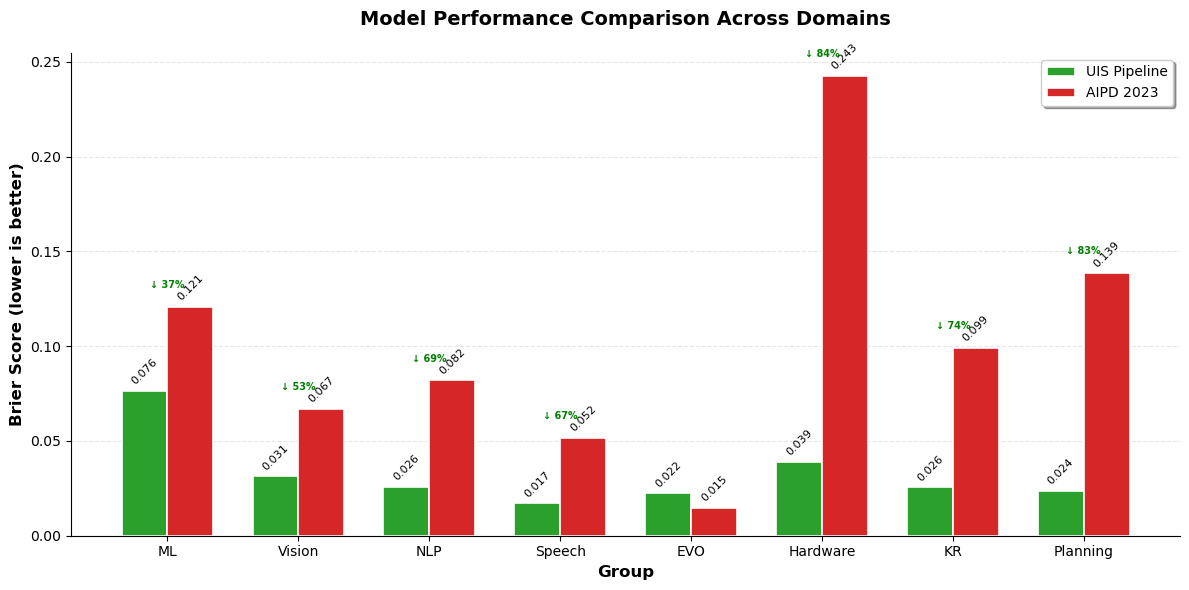

Mean Our Barier score: 0.03262463525523886
Mean Their Barier score: 0.10204876329799674


In [131]:
import matplotlib.pyplot as plt
import numpy as np

  
# Data
groups = ['ML', 'Vision', 'NLP', 'Speech', 'EVO', 'Hardware', 'KR', 'Planning']
our_scores = [0.07637029225904864,0.031260166038222466,0.02568527977988069,0.017084363131822648,0.022292100382823456,0.03893381939197818,0.02562014256677192,0.02375091849136286]
    
their_scores = [0.12077165485348146,0.06686572267865062,0.0819477500247959,0.051533949947147294,0.014714549640579415,0.24272630178268487,0.099271725405758,0.1385584520508763]

# Setup
x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

# Bars
bars1 = ax.bar(x - width/2, our_scores, width, label='UIS Pipeline', 
               color='#2ca02c', edgecolor='white', linewidth=1.2)
bars2 = ax.bar(x + width/2, their_scores, width, label='AIPD 2023', 
               color='#d62728', edgecolor='white', linewidth=1.2)

# Labels & title
ax.set_ylabel('Brier Score (lower is better)', fontsize=12, fontweight='bold')
ax.set_xlabel('Group', fontsize=12, fontweight='bold')
ax.set_title('Model Performance Comparison Across Domains', fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=10)
ax.legend(loc='upper right', frameon=True, fancybox=True, shadow=True)

# Add value labels on bars
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=8, rotation=45)

# Grid & styling
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Improvement annotations (optional)
for i, (our, their) in enumerate(zip(our_scores, their_scores)):
    improvement = ((their - our) / their) * 100
    if improvement > 0:
        ax.annotate(f'↓ {improvement:.0f}%', 
                    xy=(x[i], max(our, their) + 0.01),
                    ha='center', fontsize=7, color='green', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Mean Our Barier score: {np.mean(our_scores)}")
print(f"Mean Their Barier score: {np.mean(their_scores)}")
# Optional: Save figure
fig.savefig('brier_scores_comparison_100.png', dpi=300, bbox_inches='tight')

In [16]:
from briertools import BrierScorer

y_true = list(llm["overall_ai_score"])
y_pred_our = list(llm["similarity_100"])
# y_pred_their = their_work_binary_score

brier_scorer = BrierScorer()
brier_score_our = brier_scorer.score(y_true, y_pred_our)
# brier_score_their = brier_scorer.score(y_true, y_pred_their)

print('-------------')

print(f"Our brierscore: {brier_score_our}")
# print(f"Their brierscore: {brier_score_their}")


-------------
Our brierscore: 0.10648873996570755


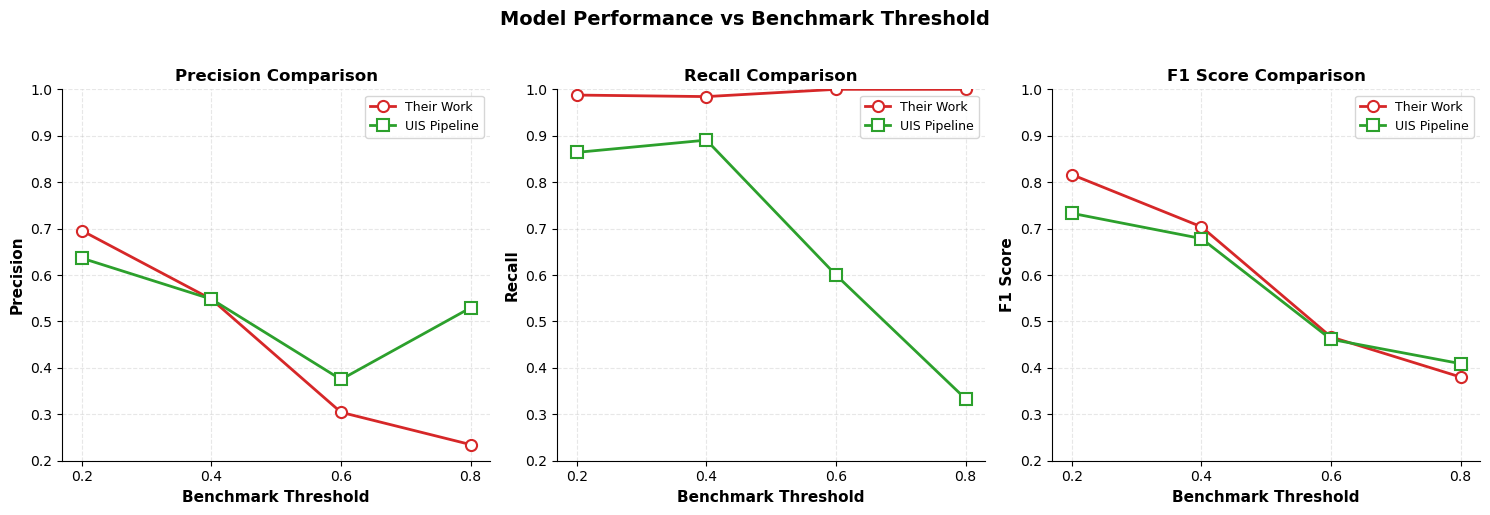

In [134]:
import matplotlib.pyplot as plt
import numpy as np

thresholds = [0.2, 0.4, 0.6, 0.8]


# Their metrics
their_precision = [0.6956521739130435, 0.5478260869565217, 0.30434782608695654, 0.23478260869565218]
their_recall = [0.9876543209876543, 0.984375, 1.0, 1.0]
their_f1 = [0.8163265306122449, 0.7039106145251397, 0.4666666666666667, 0.38028169014084506]


    
    
# Our metrics
our_precision = [0.6363636363636364, 0.5480769230769231, 0.375, 0.5294117647058824]
our_recall = [0.8641975308641975, 0.890625, 0.6, 0.3333333333333333]
our_f1 = [0.7329842931937173, 0.6785714285714286, 0.46153846153846156, 0.4090909090909091]

# Create 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Model Performance vs Benchmark Threshold', fontsize=14, fontweight='bold', y=1.02)

metrics = [
    ('Precision', their_precision, our_precision, '#d62728', '#2ca02c', [0.2, 1]),
    ('Recall', their_recall, our_recall, '#d62728', '#2ca02c', [0.2, 1]),
    ('F1 Score', their_f1, our_f1, '#d62728', '#2ca02c', [0.2, 1])
]

for ax, (title, their_vals, our_vals, color_their, color_our, ylim) in zip(axes, metrics):
    ax.plot(thresholds, their_vals, 'o-', linewidth=2, markersize=8, 
            color=color_their, label='Their Work', markerfacecolor='white', markeredgewidth=1.5)
    ax.plot(thresholds, our_vals, 's-', linewidth=2, markersize=8, 
            color=color_our, label='UIS Pipeline', markerfacecolor='white', markeredgewidth=1.5)
    
    ax.set_xlabel('Benchmark Threshold', fontsize=11, fontweight='bold')
    ax.set_ylabel(title, fontsize=11, fontweight='bold')
    ax.set_title(f'{title} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(thresholds)
    ax.set_ylim(ylim)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='best', fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

fig.savefig('find_threshold_100.png', dpi=300, bbox_inches='tight')

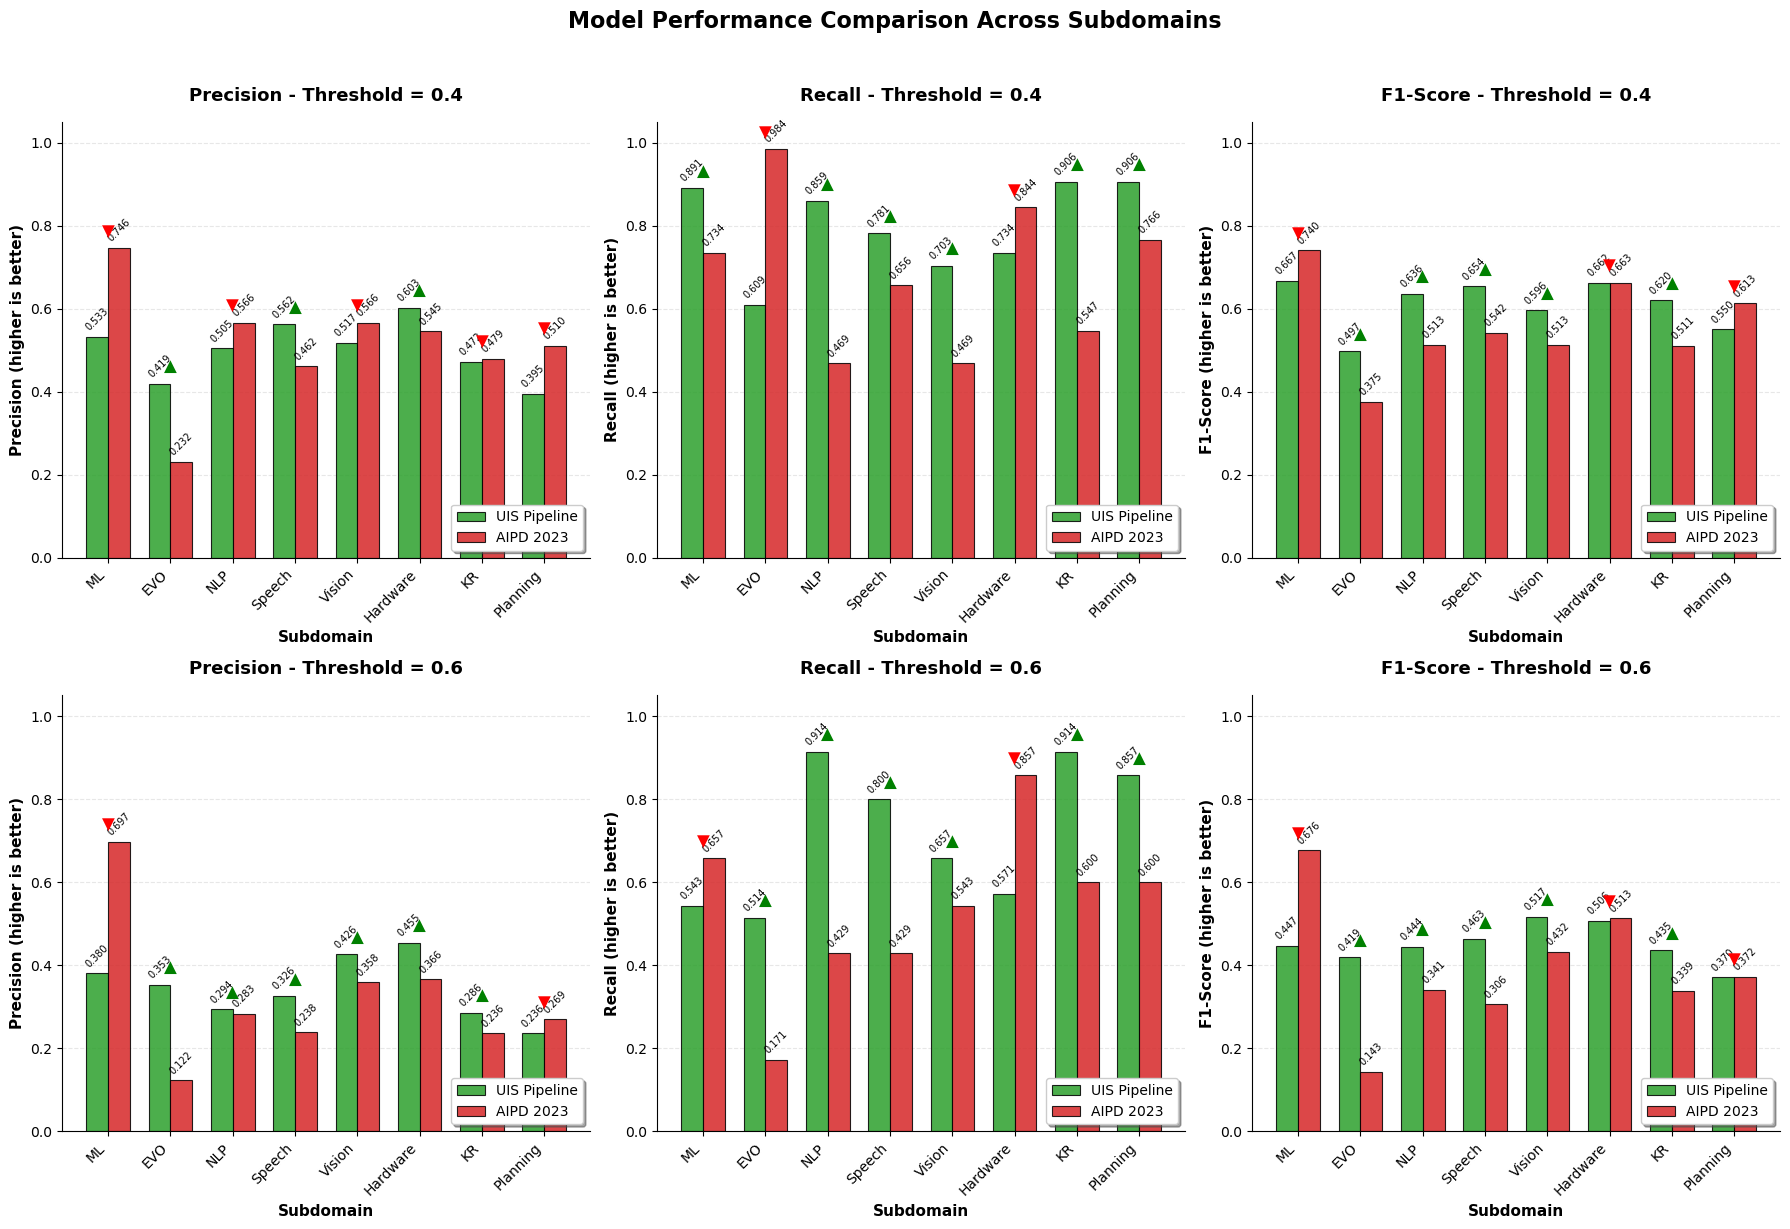

In [135]:
import matplotlib.pyplot as plt
import numpy as np

# Data
subdomains = ['ML', 'EVO', 'NLP', 'Speech', 'Vision', 'Hardware', 'KR', 'Planning']
    




# Threshold 0.4 metrics

their_precision_4 = [0.746031746031746, 0.23161764705882354, 0.5660377358490566, 0.46153846153846156, 0.5660377358490566, 0.5454545454545454, 0.4794520547945205, 0.5104166666666666]
their_recall_4 = [0.734375, 0.984375, 0.46875, 0.65625, 0.46875, 0.84375, 0.546875, 0.765625]
their_f1_4 = [0.7401574803149606, 0.375, 0.5128205128205128, 0.5419354838709678, 0.5128205128205128, 0.6625766871165644, 0.5109489051094891, 0.6125]

our_precision_4 = [0.5327102803738317, 0.41935483870967744, 0.5045871559633027, 0.5617977528089888, 0.5172413793103449, 0.6025641025641025, 0.4715447154471545, 0.3945578231292517]
our_recall_4 = [0.890625, 0.609375, 0.859375, 0.78125, 0.703125, 0.734375, 0.90625, 0.90625]
our_f1_4 = [0.6666666666666666, 0.4968152866242038, 0.6358381502890174, 0.6535947712418301, 0.5960264900662252, 0.6619718309859155, 0.6203208556149733, 0.5497630331753555]

    
     
  


# Threshold 0.6 metrics
their_precision_6 = [0.696969696969697, 0.12244897959183673, 0.2830188679245283, 0.23809523809523808, 0.3584905660377358, 0.36585365853658536, 0.23595505617977527, 0.2692307692307692]
their_recall_6 = [0.6571428571428571, 0.17142857142857143, 0.42857142857142855, 0.42857142857142855, 0.5428571428571428, 0.8571428571428571, 0.6, 0.6]  
their_f1_6 = [0.6764705882352942, 0.14285714285714285, 0.3409090909090909, 0.30612244897959184, 0.4318181818181818, 0.5128205128205128, 0.3387096774193548, 0.37168141592920356]



our_precision_6 = [0.38, 0.35294117647058826, 0.29357798165137616, 0.32558139534883723, 0.42592592592592593, 0.45454545454545453, 0.2857142857142857, 0.23622047244094488]
our_recall_6 = [0.5428571428571428, 0.5142857142857142, 0.9142857142857143, 0.8, 0.6571428571428571, 0.5714285714285714, 0.9142857142857143, 0.8571428571428571]
our_f1_6 = [0.4470588235294118, 0.4186046511627907, 0.4444444444444444, 0.4628099173553719, 0.5168539325842697, 0.5063291139240507, 0.43537414965986393, 0.37037037037037035]

# Setup
x = np.arange(len(subdomains))
width = 0.35
thresholds = [
    ('Threshold = 0.4', 
     [('Precision', our_precision_4, their_precision_4),
      ('Recall', our_recall_4, their_recall_4),
      ('F1-Score', our_f1_4, their_f1_4)]),
    ('Threshold = 0.6',
     [('Precision', our_precision_6, their_precision_6),
      ('Recall', our_recall_6, their_recall_6),
      ('F1-Score', our_f1_6, their_f1_6)])
]

# Create figure with 2 rows and 3 columns
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Model Performance Comparison Across Subdomains', fontsize=16, fontweight='bold', y=1.02)

colors = ['#2ca02c', '#d62728']  # Green for UIS Pipeline, Red for AIPD 2023
threshold_titles = ['Threshold = 0.4', 'Threshold = 0.6']

# Create plots for each threshold
for row_idx, (threshold_title, metrics_list) in enumerate(thresholds):
    for col_idx, (metric_name, our_vals, their_vals) in enumerate(metrics_list):
        ax = axes[row_idx, col_idx]
        
        # Bars
        bars1 = ax.bar(x - width/2, our_vals, width, label='UIS Pipeline', 
                       color=colors[0], edgecolor='black', linewidth=0.8, alpha=0.85)
        bars2 = ax.bar(x + width/2, their_vals, width, label='AIPD 2023', 
                       color=colors[1], edgecolor='black', linewidth=0.8, alpha=0.85)
        
        # Value labels on bars
        for bar in bars1:
            height = bar.get_height()
            ax.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=7, rotation=45)
        
        for bar in bars2:
            height = bar.get_height()
            ax.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=7, rotation=45)
        
        # Labels and formatting
        ax.set_ylabel(f'{metric_name} (higher is better)', fontsize=11, fontweight='bold')
        ax.set_xlabel('Subdomain', fontsize=11, fontweight='bold')
        ax.set_title(f'{metric_name} - {threshold_title}', fontsize=13, fontweight='bold', pad=15)
        ax.set_xticks(x)
        ax.set_xticklabels(subdomains, fontsize=10, rotation=45, ha='right')
        ax.set_ylim(0, 1.05)
        ax.legend(loc='lower right', frameon=True, fancybox=True, shadow=True)
        ax.grid(axis='y', alpha=0.3, linestyle='--')
        ax.set_axisbelow(True)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        # Highlight areas where we are better
        for i, (our, their) in enumerate(zip(our_vals, their_vals)):
            if our > their:
                ax.annotate('▲', xy=(x[i], max(our, their) + 0.03), 
                           ha='center', fontsize=12, color='green', fontweight='bold')
            elif our < their:
                ax.annotate('▼', xy=(x[i], max(our, their) + 0.03), 
                           ha='center', fontsize=12, color='red', fontweight='bold')

plt.tight_layout()
plt.show()

# Save figure
fig.savefig('precision_recall_f1_comparison_both_thresholds_100.png', dpi=300, bbox_inches='tight')

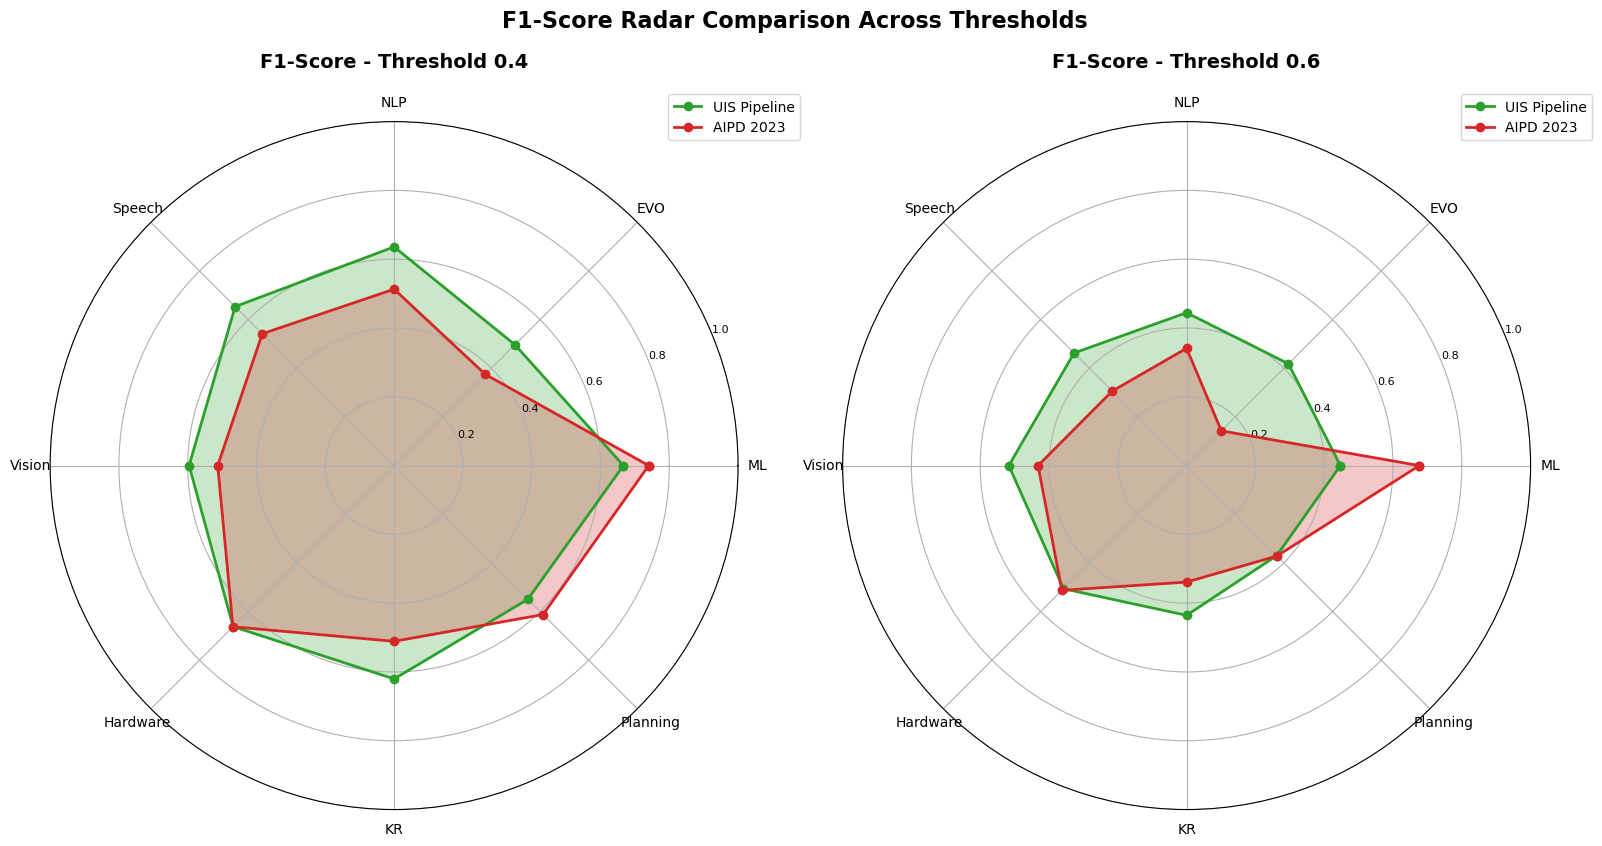

In [136]:
import matplotlib.pyplot as plt
import numpy as np

subdomains = ['ML', 'EVO', 'NLP', 'Speech', 'Vision', 'Hardware', 'KR', 'Planning']

# Threshold 0.4 F1 scores
their_f1_4 = [0.7401574803149606, 0.375, 0.5128205128205128, 0.5419354838709678, 0.5128205128205128, 0.6625766871165644, 0.5109489051094891, 0.6125]
our_f1_4 = [0.6666666666666666, 0.4968152866242038, 0.6358381502890174, 0.6535947712418301, 0.5960264900662252, 0.6619718309859155, 0.6203208556149733, 0.5497630331753555]


# Threshold 0.6 F1 scores
their_f1_6 = [0.6764705882352942, 0.14285714285714285, 0.3409090909090909, 0.30612244897959184, 0.4318181818181818, 0.5128205128205128, 0.3387096774193548, 0.37168141592920356]
our_f1_6 = [0.4470588235294118, 0.4186046511627907, 0.4444444444444444, 0.4628099173553719, 0.5168539325842697, 0.5063291139240507, 0.43537414965986393, 0.37037037037037035]

# Radar chart setup
angles = np.linspace(0, 2 * np.pi, len(subdomains), endpoint=False).tolist()
angles += angles[:1]  # close the loop

# Create figure with 2 subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 8), subplot_kw={'projection': 'polar'})

# Plot for Threshold 0.4 (Left)
our_f1_4_closed = our_f1_4 + our_f1_4[:1]
their_f1_4_closed = their_f1_4 + their_f1_4[:1]

axes[0].plot(angles, our_f1_4_closed, 'o-', linewidth=2, label='UIS Pipeline', color='#2ca02c')
axes[0].fill(angles, our_f1_4_closed, alpha=0.25, color='#2ca02c')
axes[0].plot(angles, their_f1_4_closed, 'o-', linewidth=2, label='AIPD 2023', color='#d62728')
axes[0].fill(angles, their_f1_4_closed, alpha=0.25, color='#d62728')

axes[0].set_xticks(angles[:-1])
axes[0].set_xticklabels(subdomains, fontsize=10)
axes[0].set_ylim(0, 1)
axes[0].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
axes[0].set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8)
axes[0].set_title('F1-Score - Threshold 0.4', fontsize=14, fontweight='bold', pad=20)
axes[0].legend(loc='upper right', bbox_to_anchor=(1.1, 1.05))

# Plot for Threshold 0.6 (Right)
our_f1_6_closed = our_f1_6 + our_f1_6[:1]
their_f1_6_closed = their_f1_6 + their_f1_6[:1]

axes[1].plot(angles, our_f1_6_closed, 'o-', linewidth=2, label='UIS Pipeline', color='#2ca02c')
axes[1].fill(angles, our_f1_6_closed, alpha=0.25, color='#2ca02c')
axes[1].plot(angles, their_f1_6_closed, 'o-', linewidth=2, label='AIPD 2023', color='#d62728')
axes[1].fill(angles, their_f1_6_closed, alpha=0.25, color='#d62728')

axes[1].set_xticks(angles[:-1])
axes[1].set_xticklabels(subdomains, fontsize=10)
axes[1].set_ylim(0, 1)
axes[1].set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
axes[1].set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8)
axes[1].set_title('F1-Score - Threshold 0.6', fontsize=14, fontweight='bold', pad=20)
axes[1].legend(loc='upper right', bbox_to_anchor=(1.1, 1.05))

# Add overall title
fig.suptitle('F1-Score Radar Comparison Across Thresholds', fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

# Save figure
fig.savefig('f1_comparison_both_thresholds_100.png', dpi=300, bbox_inches='tight')